# California Housing - Regression

Predict the median house value of California districts (1990 census) and compare a linear baseline with tree-based ensembles.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:.3f}")
RANDOM_STATE = 42

## 1. Data Overview

In [2]:
# Load the dataset as a DataFrame (target: MedHouseVal, in $100k)
housing = fetch_california_housing(as_frame=True)
df = housing.frame

In [3]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.325,41.000,6.984,1.024,322.000,2.556,37.880,-122.230,4.526
1,8.301,21.000,6.238,0.972,2401.000,2.110,37.860,-122.220,3.585
2,7.257,52.000,8.288,1.073,496.000,2.802,37.850,-122.240,3.521
3,5.643,52.000,5.817,1.073,558.000,2.548,37.850,-122.250,3.413
4,3.846,52.000,6.282,1.081,565.000,2.181,37.850,-122.250,3.422


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.000,3.871,1.900,0.500,2.563,3.535,4.743,15.000
HouseAge,20640.000,28.639,12.586,1.000,18.000,29.000,37.000,52.000
AveRooms,20640.000,5.429,2.474,0.846,4.441,5.229,6.052,141.909
AveBedrms,20640.000,1.097,0.474,0.333,1.006,1.049,1.100,34.067
Population,20640.000,1425.477,1132.462,3.000,787.000,1166.000,1725.000,35682.000
AveOccup,20640.000,3.071,10.386,0.692,2.430,2.818,3.282,1243.333
Latitude,20640.000,35.632,2.136,32.540,33.930,34.260,37.710,41.950
Longitude,20640.000,-119.570,2.004,-124.350,-121.800,-118.490,-118.010,-114.310
MedHouseVal,20640.000,2.069,1.154,0.150,1.196,1.797,2.647,5.000


## 2. Exploratory Data Analysis

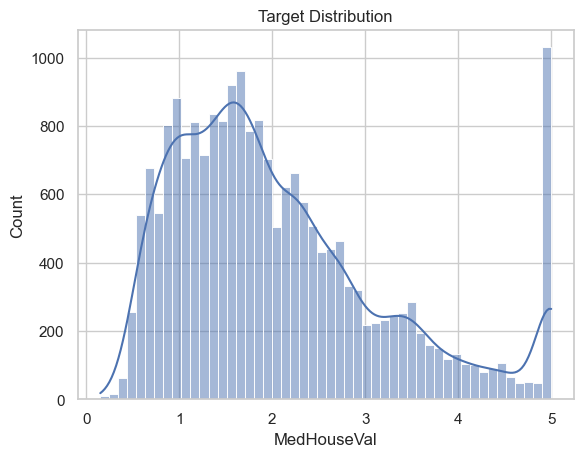

In [6]:
sns.histplot(df['MedHouseVal'], bins=50, kde=True)
plt.title('Target Distribution')
plt.show()

The target is right-skewed and capped at 5.0 ($500k), visible as a spike at the right edge.

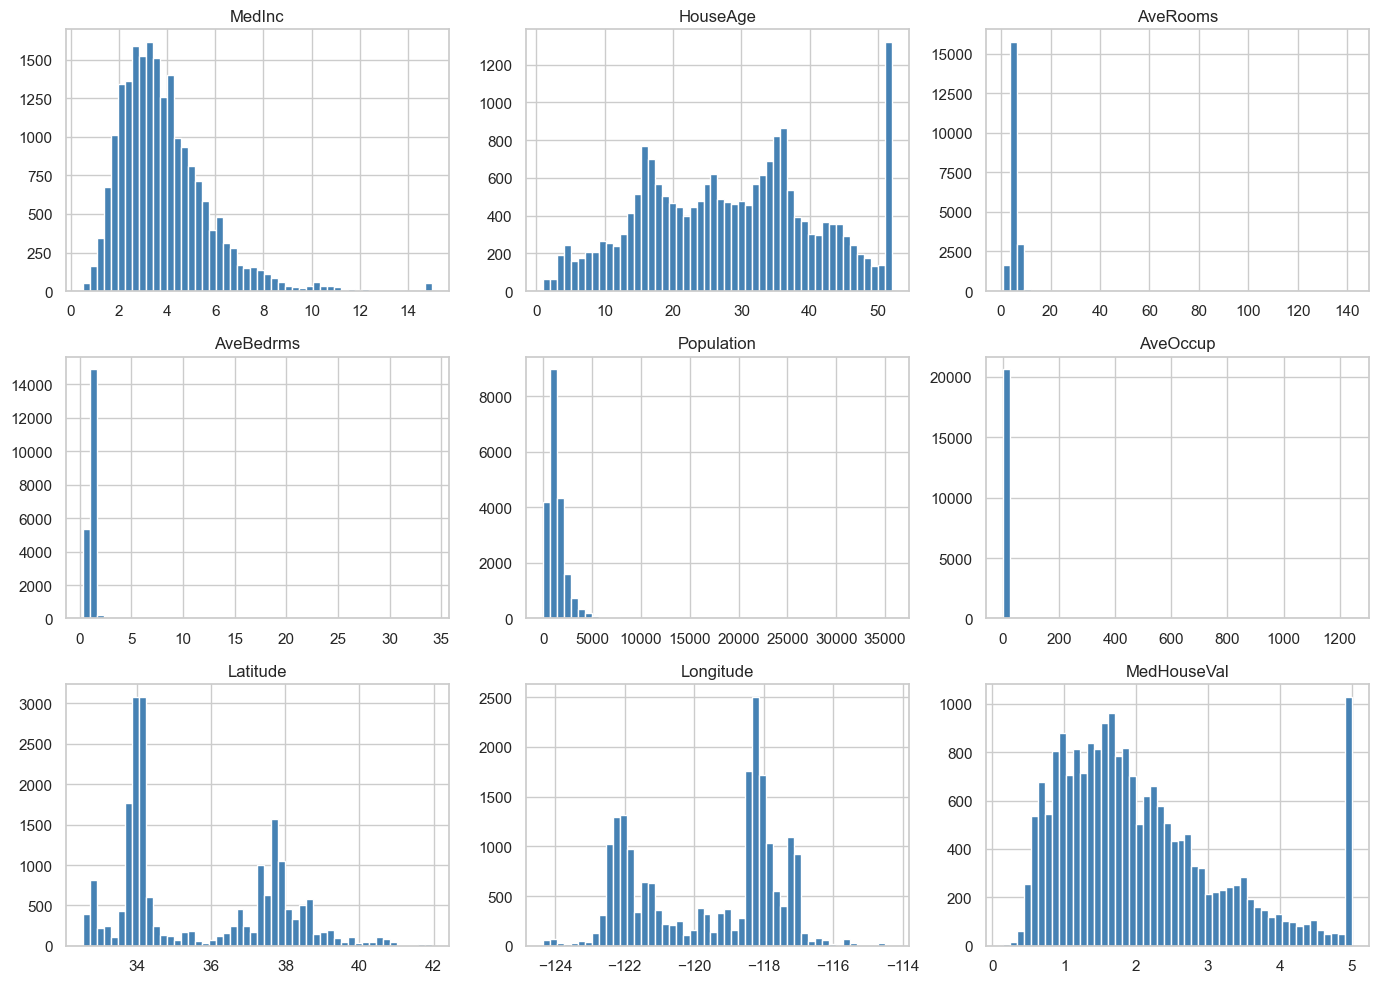

In [7]:
df.hist(bins=50, figsize=(14, 10), color='steelblue', edgecolor='white')
plt.tight_layout()
plt.show()

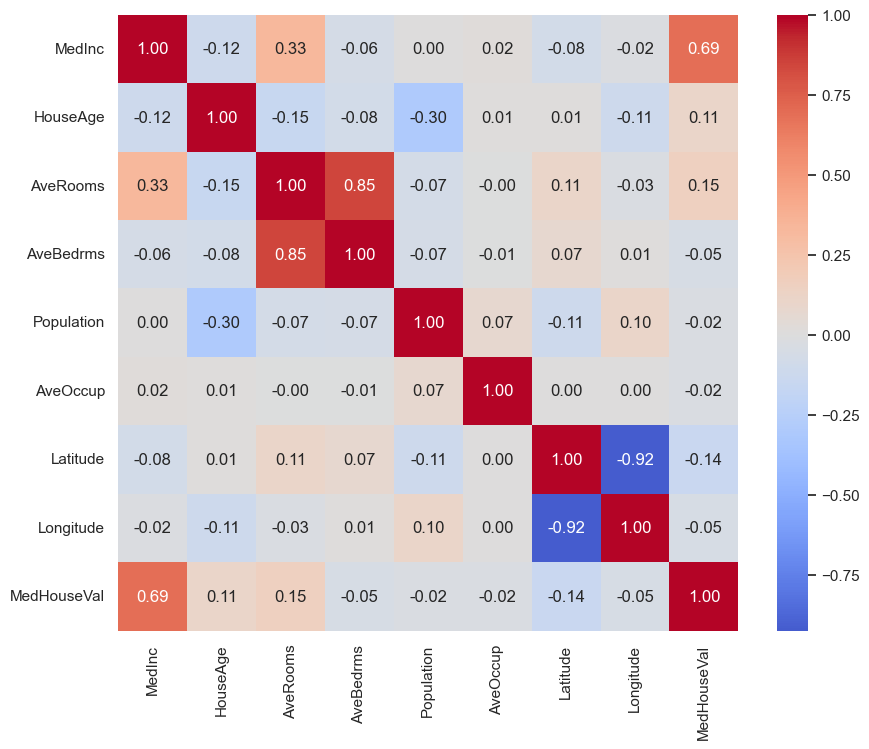

In [8]:
# Correlation between features and the target
plt.figure(figsize=(10, 8))
corr = df.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

`MedInc` has the strongest correlation with the target (~0.69).

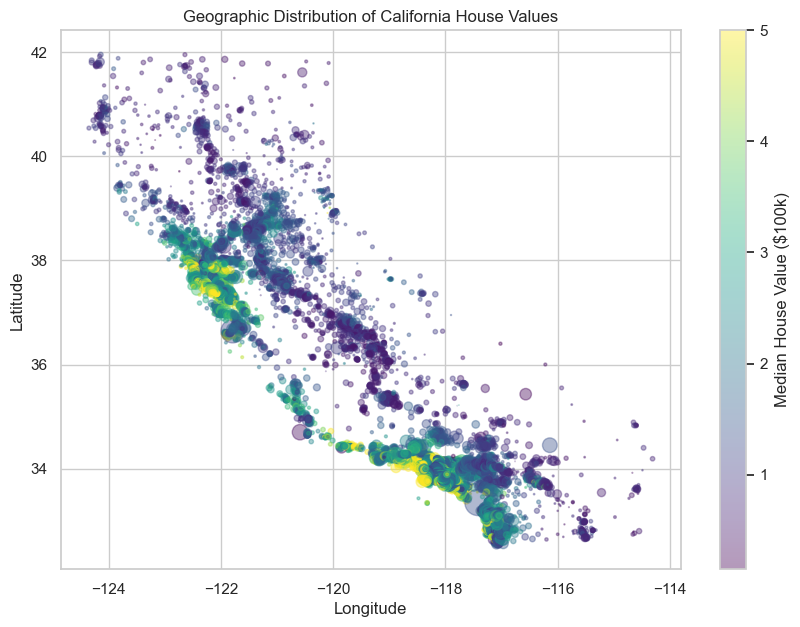

In [9]:
# Point size = population, color = house value
plt.figure(figsize=(10, 7))
plt.scatter(df['Longitude'], df['Latitude'],
            c=df['MedHouseVal'], cmap='viridis',
            s=df['Population']/100, alpha=0.4)
plt.colorbar(label='Median House Value ($100k)')
plt.title('Geographic Distribution of California House Values')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

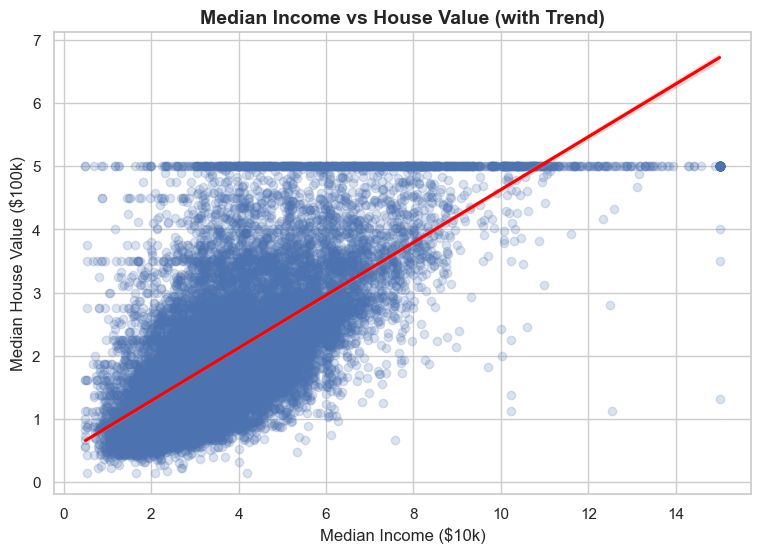

In [10]:
plt.figure(figsize=(9, 6))
sns.regplot(data=df, x='MedInc', y='MedHouseVal',
            scatter_kws={'alpha': 0.2},          # transparent points
            line_kws={'color': 'red'})           # red trend line
plt.title('Median Income vs House Value (with Trend)', fontsize=14, fontweight='bold')
plt.xlabel('Median Income ($10k)')
plt.ylabel('Median House Value ($100k)')
plt.show()

## 3. Train / Test Split

In [11]:
X = df.drop(columns='MedHouseVal')
y = df['MedHouseVal']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)



## 4. Models

Linear Regression needs scaled features, so it is wrapped in a pipeline. Tree models do not need scaling.

In [12]:
models = {
    'Linear Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LinearRegression())
    ]),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=RANDOM_STATE)
}

### Cross-Validation

5-fold CV on the training set only, so the test set stays unseen.

In [13]:
cv_results = {}
for name, model in models.items():
    # sklearn returns negative RMSE, so flip the sign
    scores = -cross_val_score(model, X_train, y_train, cv=5,
                              scoring='neg_root_mean_squared_error')
    cv_results[name] = scores
    print(f'{name:<20} RMSE: {scores.mean():.3f} (+/- {scores.std():.3f})')

Linear Regression    RMSE: 0.721 (+/- 0.010)


Random Forest        RMSE: 0.512 (+/- 0.005)


Gradient Boosting    RMSE: 0.534 (+/- 0.007)


### Test Set Evaluation

In [14]:
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
        'R2': r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results).set_index('Model').sort_values('RMSE')
results_df

,MAE,RMSE,R2
Model,,,
Random Forest,0.328,0.505,0.805
Gradient Boosting,0.372,0.542,0.776
Linear Regression,0.533,0.746,0.576


## 5. Hyperparameter Tuning

Random Forest gave the best results, so we tune it with `RandomizedSearchCV`. It tries random combinations from the grid, which is much faster than a full grid search.

In [15]:
param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 0.5, 1.0]  # share of features tried at each split
}

search = RandomizedSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=15,  # number of random combinations to try
    cv=3,
    scoring='neg_root_mean_squared_error',
    random_state=RANDOM_STATE
)
search.fit(X_train, y_train)

print('Best params:', search.best_params_)
print(f'Best CV RMSE: {-search.best_score_:.3f}')

Best params: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20}
Best CV RMSE: 0.501


In [16]:
# Evaluate the tuned model on the test set and add it to the comparison
tuned_rf = search.best_estimator_
models['Random Forest (Tuned)'] = tuned_rf
y_pred = tuned_rf.predict(X_test)

results_df.loc['Random Forest (Tuned)'] = [
    mean_absolute_error(y_test, y_pred),
    np.sqrt(mean_squared_error(y_test, y_pred)),
    r2_score(y_test, y_pred)
]
results_df = results_df.sort_values('RMSE')
results_df

,MAE,RMSE,R2
Model,,,
Random Forest (Tuned),0.329,0.495,0.813
Random Forest,0.328,0.505,0.805
Gradient Boosting,0.372,0.542,0.776
Linear Regression,0.533,0.746,0.576


### HistGradientBoosting

The tuned Random Forest is large (~80 MB on disk), which is impractical for the app. `HistGradientBoostingRegressor` is a faster boosting model that bins features into histograms and produces a much smaller model. We tune it the same way.

In [17]:
param_dist = {
    'learning_rate': [0.05, 0.1, 0.2],
    'max_iter': [200, 500, 1000],  # max number of boosting rounds
    'max_leaf_nodes': [15, 31, 63],
    'min_samples_leaf': [20, 50],
    'l2_regularization': [0.0, 1.0]
}

search = RandomizedSearchCV(
    HistGradientBoostingRegressor(random_state=RANDOM_STATE),
    param_distributions=param_dist,
    n_iter=15,
    cv=3,
    scoring='neg_root_mean_squared_error',
    random_state=RANDOM_STATE
)
search.fit(X_train, y_train)

print('Best params:', search.best_params_)
print(f'Best CV RMSE: {-search.best_score_:.3f}')

Best params: {'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_iter': 500, 'learning_rate': 0.05, 'l2_regularization': 0.0}
Best CV RMSE: 0.465


In [18]:
tuned_hgb = search.best_estimator_
models['HistGradientBoosting (Tuned)'] = tuned_hgb
y_pred = tuned_hgb.predict(X_test)

results_df.loc['HistGradientBoosting (Tuned)'] = [
    mean_absolute_error(y_test, y_pred),
    np.sqrt(mean_squared_error(y_test, y_pred)),
    r2_score(y_test, y_pred)
]
results_df = results_df.sort_values('RMSE')
results_df

,MAE,RMSE,R2
Model,,,
HistGradientBoosting (Tuned),0.288,0.442,0.851
Random Forest (Tuned),0.329,0.495,0.813
Random Forest,0.328,0.505,0.805
Gradient Boosting,0.372,0.542,0.776
Linear Regression,0.533,0.746,0.576


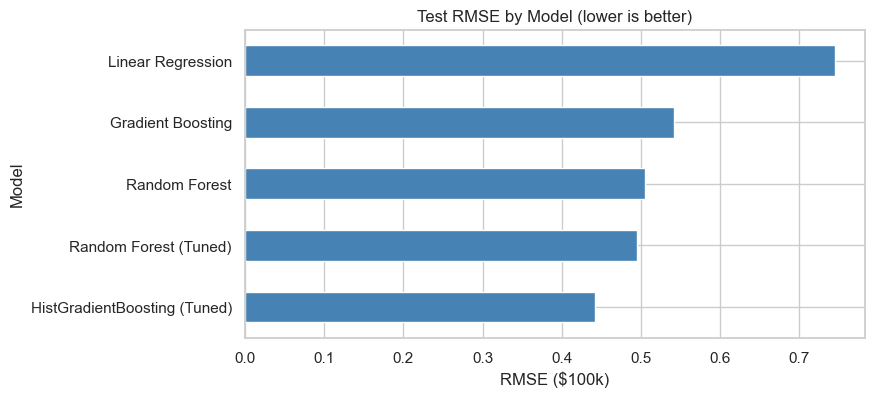

In [19]:
results_df['RMSE'].plot(kind='barh', color='steelblue', figsize=(8, 4))
plt.title('Test RMSE by Model (lower is better)')
plt.xlabel('RMSE ($100k)')
plt.show()

## 6. Best Model Analysis

Best model: HistGradientBoosting (Tuned)


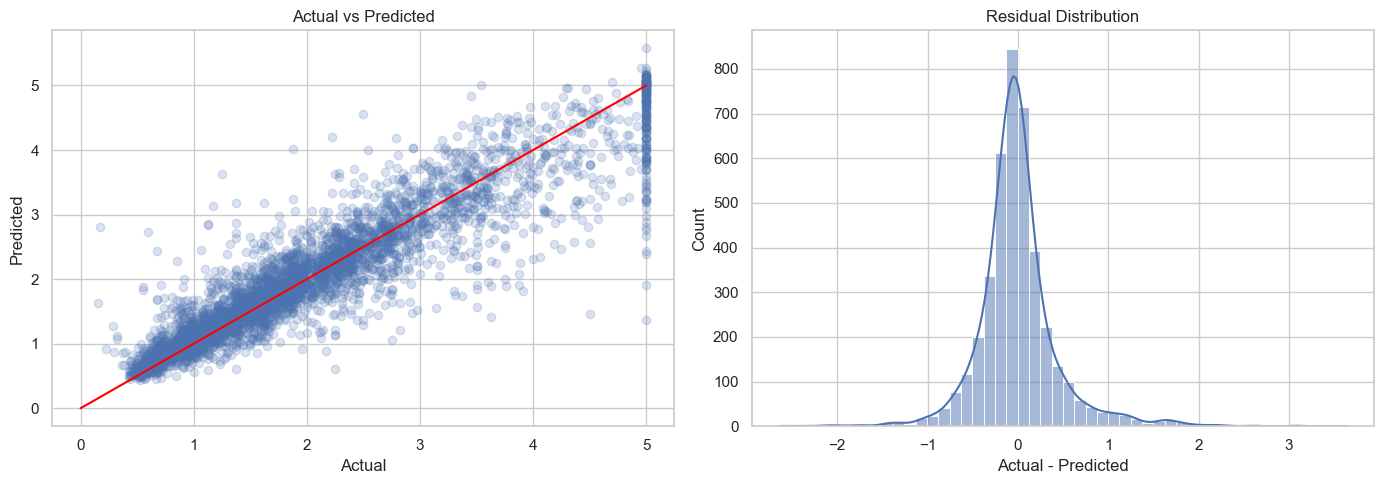

In [20]:
best_name = results_df.index[0]
best_model = models[best_name]
y_pred = best_model.predict(X_test)
residuals = y_test - y_pred
print('Best model:', best_name)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Predicted vs actual: points should lie close to the red line
axes[0].scatter(y_test, y_pred, alpha=0.2)
axes[0].plot([0, 5], [0, 5], color='red')
axes[0].set_title('Actual vs Predicted')
axes[0].set_xlabel('Actual')
axes[0].set_ylabel('Predicted')

# Residuals should be centered around zero
sns.histplot(residuals, bins=50, kde=True, ax=axes[1])
axes[1].set_title('Residual Distribution')
axes[1].set_xlabel('Actual - Predicted')

plt.tight_layout()
plt.show()

### Feature Importance

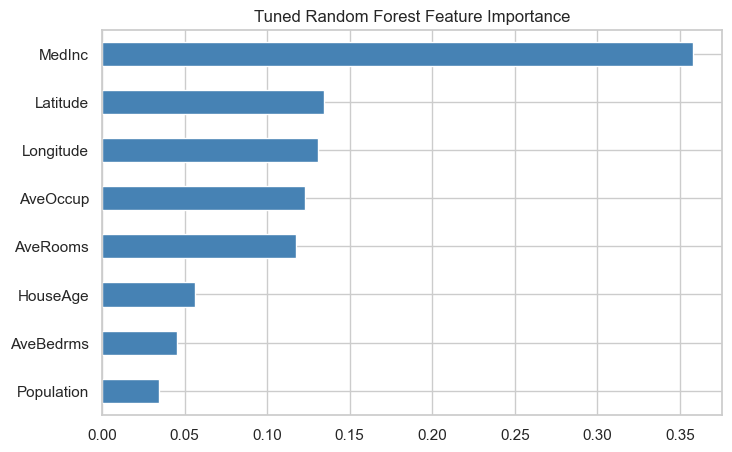

In [21]:
# Impurity-based importance from the tuned Random Forest
importances = pd.Series(tuned_rf.feature_importances_, index=X.columns)
importances.sort_values().plot(kind='barh', color='steelblue', figsize=(8, 5))
plt.title('Tuned Random Forest Feature Importance')
plt.show()

## 7. Conclusion

- **Tuned HistGradientBoosting** is the best model (RMSE ~0.44, R2 ~0.85). It is also much smaller than the tuned Random Forest, so it is the model used in the Streamlit app.
- **Tuned Random Forest** comes second (RMSE ~0.50, R2 ~0.81). Tuning gave a small gain over the default Random Forest (RMSE 0.505 -> 0.495).
- Best Random Forest params: 300 trees, `max_depth=20`, `max_features='sqrt'`.
- Gradient Boosting is close behind (R2 ~0.78), while **Linear Regression** is clearly weaker (R2 ~0.58): the relationship is not linear.
- CV and test scores are close, so the models generalize well.
- In the Random Forest, `MedInc` is the most important feature, followed by location (`Latitude`, `Longitude`), `AveOccup` and `AveRooms`.
